Fig3,Fig4,Ext data Fig1

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


In [5]:
from core_fct.mod_process import OSCAR
from core_fct.fct_loadP import load_all_param
from core_fct.fct_genMC import generate_config
from run_scripts.get_SSP_drivers import For_hist
from run_scripts.get_SSP_drivers import For_scen

In [3]:
For_scen = For_scen.sel(year=slice(2014,2100))

loading primary parameters


/home/fb/anaconda3/lib/python3.8/site-packages/xarray/core/missing.py:559: FutureWarning: Passing method to Int64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/fb/anaconda3/lib/python3.8/site-packages/xarray/core/missing.py:560: FutureWarning: Passing method to Int64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imax = index.get_loc(maxval, method="nearest")
/home/fb/anaconda3/lib/python3.8/site-packages/xarray/core/missing.py:559: FutureWarning: Passing method to Int64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/fb/anaconda3/lib/python3.8/site-packages/xarray/core/missing.py:560: FutureWarning: Passing method to Int64Index.get_loc is deprecated and will raise in a future v

# 甲烷控制效应
以Global methane pledge (GMP)

In [33]:
For_scen_tmp = For_scen.sel(year=slice(None, 2050)).copy(deep=True).drop_vars('D_CH4')
## 生成三个排放情景

## 2014-2019 (CEDS)
CEDS_CH4 = [270.2496358,269.8280079,267.9817751,268.1138598,270.537411,271.6083044]
CEDS_NOX = [38.59678516,37.98745474,37.48333497,37.43483474,37.16926467,36.81225668]
CEDS_CO = [247.089963,241.5313653,233.9000087,230.9691292,228.7215534,226.6449276]
CEDS_VOC = [149.9870685,148.9745692,148.276486,148.5098291,147.521796,146.6675455]

For_scen_real = For_scen_tmp.copy(deep=True).sel(scen=['SSP2-4.5','SSP2-4.5','SSP2-4.5']).assign_coords(scen=np.array(['middle','clean','polluted']))
For_scen_real.E_CH4[0,6:] -= (For_scen_real.E_CH4.sel(year=2019).sum('reg_land').values-CEDS_CH4[-1])
for i in range(len(CEDS_CH4)):
    For_scen_real.E_CH4[:,i] *=0
    For_scen_real.E_CH4[0,i] +=CEDS_CH4[i]
for var in ['E_NOX','E_CO','E_VOC',]:
    For_scen_real[var][...,1] = For_scen_tmp[var].copy(deep=True).sel(scen='SSP1-1.9')
    For_scen_real[var][...,2] = For_scen_tmp[var].copy(deep=True).sel(scen='SSP3-7.0')
For_scen_real.E_NOX[0,6:] -= (For_scen_real.E_NOX.sel(year=2019).sum('reg_land').values-CEDS_NOX[-1])
For_scen_real.E_CO[0,6:] -= (For_scen_real.E_CO.sel(year=2019).sum('reg_land').values-CEDS_CO[-1])
For_scen_real.E_VOC[0,6:] -= (For_scen_real.E_VOC.sel(year=2019).sum('reg_land').values-CEDS_VOC[-1])

for i in range(len(CEDS_CH4)):
    For_scen_real.E_NOX[:,i] *=0
    For_scen_real.E_NOX[0,i] +=CEDS_NOX[i]
    For_scen_real.E_CO[:,i] *=0
    For_scen_real.E_CO[0,i] +=CEDS_CO[i]
    For_scen_real.E_VOC[:,i] *=0
    For_scen_real.E_VOC[0,i] +=CEDS_VOC[i]

In [7]:
Par0 = load_all_param(mod_region='RCP_5reg')
Par = generate_config(Par0, nMC=200)
Par = xr.merge([Par, For_hist.drop([VAR for VAR in For_hist if 'year' in For_hist[VAR].dims])])
For_hist = For_hist.drop([VAR for VAR in For_hist if 'year' not in For_hist[VAR].dims])

Out_hist = OSCAR(Ini=None, Par=Par, For=For_hist)

loading primary parameters
generating MC configurations
OSCAR_v3 running
year = 2014 (nt = 3)
total running time: 14.6 minutes


In [8]:
Ini = Out_hist.isel(year=-1, drop=True)
Ini['D_CH4'] = 1822.61-Par0.CH4_0 # https://gml.noaa.gov/webdata/ccgg/trends/ch4/ch4_annmean_gl.txt

For_scen_tmp = For_scen.sel(year=slice(None, 2050)).copy(deep=True).drop_vars('D_CH4')

x2_OH_NOX = 0.00456
x2_OH_CO = -0.00024
x2_OH_VOC = -0.00027

Par_tmp = Par.copy(deep=True)
Par_tmp.kOH_is_Log.values = np.array([False]*200)
Par_tmp.x2_OH_NOX.values = np.array([x2_OH_NOX]*200)
Par_tmp.x2_OH_CO.values = np.array([x2_OH_CO]*200)
Par_tmp.x2_OH_VOC.values = np.array(x2_OH_VOC)

Par_tmp['t_OH_CH4'] = 11.2

In [9]:
For_scen_gmp = For_scen_real.copy(deep=True)

### 2030相对于2020减排30%，假设之后保持固定

E_CH4_2020_2030 = np.linspace(For_scen_gmp['E_CH4'].sel(year=2020),For_scen_gmp['E_CH4'].sel(year=2020)*0.7,11)
For_scen_gmp['E_CH4'][:,2020-2014:2030-2014+1,:] = np.transpose(E_CH4_2020_2030,[1,0,2])
For_scen_gmp['E_CH4'][:,2030-2014+1:,:] = np.transpose(np.array([E_CH4_2020_2030[-1]]*20),[1,0,2])

In [11]:
var_keep = ['D_Eluc', 'D_Focean', 'D_Fland', 'D_Epf'] + ['tau_CH4', 'tau_N2O'] + ['RF_CH4','RF_O3t']+['D_O3t']+['f_kOH_O3P']
Out_scen_gmp = OSCAR(Ini=Ini, Par=Par_tmp, For=For_scen_gmp, var_keep=var_keep+['f_kOH','f_kOH_O3P']+['RF'], nt=4)

OSCAR_v3 running
year = 2050 (nt = 4)
total running time: 4.7 minutes


In [34]:
Out_scen_real = OSCAR(Ini=Ini, Par=Par_tmp, For=For_scen_real.sel(year=slice(2014,2050)), var_keep=var_keep+['f_kOH','f_kOH_O3P', 'D_Ebb','f_hv','D_Ewet','D_Epf_CH4','D_O3s','D_Ta', 'D_f_Qa'], nt=4)

OSCAR_v3 running
year = 2050 (nt = 4)
total running time: 4.7 minutes


In [38]:
color_list = ['k','#41B365','#741A88']

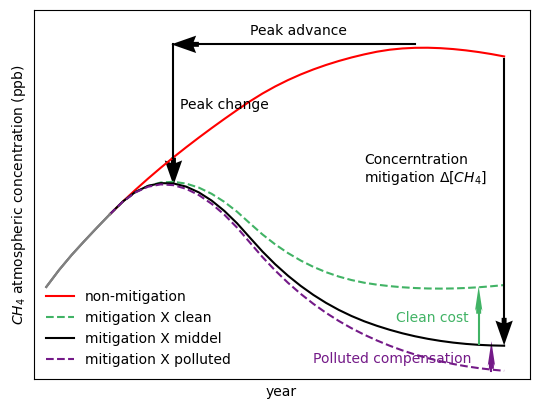

In [108]:
fig, ax = plt.subplots()

ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_real.isel(scen=0).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,label='non-mitigation',
         linestyle='-',color='r')
label_list = ['mitigation X middel','mitigation X clean','mitigation X polluted']
for i in [1,0,2]:
    if i == 0:
        linestyle = '-'
    else:
        linestyle = '--'
    ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_gmp.isel(scen=i).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,label=label_list[i],
             linestyle=linestyle,color=color_list[i])
ax.plot(Out_scen_real.year.sel(year=slice(2014,2019)),Out_scen_gmp.D_CH4.sel(year=slice(2014,2019)).mean('config')+Par0.CH4_0,color='grey')


def plot_quiver(ax,point1,point2,color='k',linestyle='-',headwidth=3.5):
    x0,y0 = point1
    x1,y1 = point2
    ax.plot([x0,x1],[y0,y1],color=color,linestyle=linestyle)
    ax.quiver(x1,y1,(x1-x0),(y1-y0),color=color, width=.01,headwidth=headwidth,)

### 环保与收益
plot_quiver(ax,(2050,2100),(2050,1785))
ax.text(2039,1950,'Concerntration\nmitigation Δ[$CH_4$]')


plot_quiver(ax,(2048,1753),(2048,1790),color=color_list[1],headwidth=1.5)
ax.text(2041.5,1780,'Clean cost',color=color_list[1])
plot_quiver(ax,(2049,1720),(2049,1723),color=color_list[2],headwidth=1.5)
ax.text(2035,1730,'Polluted compensation',color=color_list[2])


plot_quiver(ax,(2043,2118),(2026,2118),linestyle='-')
ax.text(2030,2130,'Peak advance')
plot_quiver(ax,(2024,2118),(2024,1980),linestyle='-')
ax.text(2024.5,2040,'Peak change')


ax.set_xticks([]) ##去掉标度
ax.set_yticks([])

ax.set_ylabel('$CH_4$ atmospheric concentration (ppb)')
ax.set_xlabel('year')
ax.legend(loc='lower left',frameon=False)
ax.set_xlim(2013,2052)
ax.set_ylim(1710,2160)
fig.savefig('示意图.pdf',dpi=300)

In [109]:
scen_list = []

scen_1_list = ['p','m','c']
scen_2_list = [4,3,2,1,0]

for x in scen_1_list:
    for y in scen_2_list:
        scen_list.append(x+str(y))

For_scen_gmp_change = For_scen_gmp.sel(scen=['polluted']*5+['middle']*5+['clean']*5).copy(deep=True).assign_coords(scen=np.array(scen_list))

# GMP强度
ratio = [-10,-5,0,5,10]

for y in scen_2_list:
    j = scen_2_list.index(y)
#     print(scen)
    for x in scen_1_list:
        scen = x+str(y)
        E_CH4_2020_2030 = np.linspace(For_scen_gmp_change['E_CH4'].sel(scen=scen).sel(year=2020),For_scen_gmp_change['E_CH4'].sel(scen=scen).sel(year=2020)*(0.7+ratio[j]/100),11)
        index = For_scen_gmp_change.scen.values.tolist().index(scen)
        For_scen_gmp_change['E_CH4'][:,2020-2014:2030-2014+1,index] = np.transpose(E_CH4_2020_2030,[1,0])
        For_scen_gmp_change['E_CH4'][:,2030-2014+1:,index] = np.transpose(np.array([E_CH4_2020_2030[-1]]*20),[1,0])
        
        

In [110]:
Out_scen_gmp_change_polluted = OSCAR(Ini=Ini, Par=Par_tmp, For=For_scen_gmp_change, var_keep=var_keep+['f_kOH','f_kOH_O3P']+['RF'], nt=4)

OSCAR_v3 running
year = 2050 (nt = 4)
total running time: 5.0 minutes


p2
1947.498094420394
m2
1949.0277171148068
c2
1950.612747156962


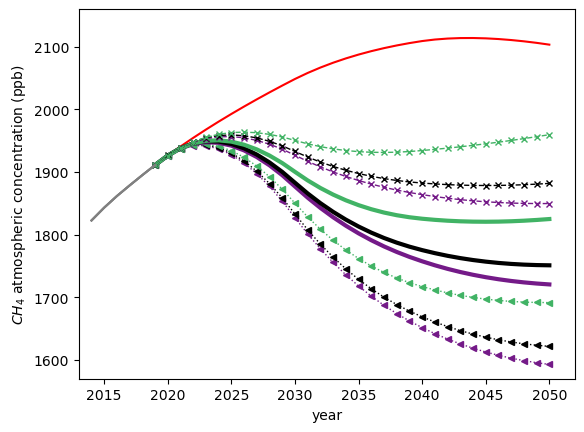

In [129]:
fig, ax = plt.subplots()

ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_real.isel(scen=0).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,#label='no-GMP',
         linestyle='-',color='r')

scen_1_list = ['p','m','c']
scen_2_list = [4,2,0]

linestyle_list = [':','-','--']
linewidth_list = [1,3,1]
color_list = ['#741A88','k','#41B365',]
marker_list = ['<','','x']

label_1_list = ['polluted','middel','clean']
label_2_list = ['20%','30%','40%']

for y in scen_2_list:
    for x in scen_1_list:
        scen = x+str(y)
        
        i = scen_1_list.index(x)
        j = scen_2_list.index(y)
        ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,
                label=label_1_list[i]+'-'+label_2_list[j],
                linestyle=linestyle_list[j],color=color_list[i],linewidth=linewidth_list[j],
               marker=marker_list[j],markersize=4
               )
        if y == 2:
            print(scen)
            print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0).max().values)
#             print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0).values)
#             print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0)[-1].values)
ax.plot(Out_scen_real.year.sel(year=slice(2014,2019)),Out_scen_gmp.D_CH4.sel(year=slice(2014,2019)).mean('config')+Par0.CH4_0,color='grey')
# ax.legend(ncol=3)


ax.set_ylabel('$CH_4$ atmospheric concentration (ppb)')
ax.set_xlabel('year')

ax.set_ylim(1570,2160)
ax.set_xlim(2013,2052)

fig.savefig('GMP.pdf',dpi=300)

In [156]:
Out_scen_gmp_change_polluted.sel(scen='c2').D_CH4.mean('config').sel(year=slice(2019,2050))-Out_scen_gmp_change_polluted.sel(scen='p2').D_CH4.mean('config').sel(year=slice(2019,2050))

<xarray.DataArray 'D_CH4' (year: 32)>
array([ 0.00000000e+00, -2.33621513e-02,  1.48799695e-01,  9.17619915e-01,
        2.23908335e+00,  4.06911554e+00,  6.36447578e+00,  9.08232790e+00,
        1.21810560e+01,  1.56205459e+01,  1.93623500e+01,  2.33696834e+01,
        2.75583193e+01,  3.18240829e+01,  3.61579144e+01,  4.05530566e+01,
        4.50038446e+01,  4.95055031e+01,  5.40541080e+01,  5.86463287e+01,
        6.32795532e+01,  6.79517206e+01,  7.25454404e+01,  7.68770911e+01,
        8.09675537e+01,  8.48370837e+01,  8.85046535e+01,  9.19877405e+01,
        9.53022608e+01,  9.84633484e+01,  1.01485088e+02,  1.04380773e+02])
Coordinates:
  * year     (year) int64 2019 2020 2021 2022 2023 ... 2046 2047 2048 2049 2050

In [157]:
Out_scen_gmp_change_polluted.sel(scen='c4').D_CH4.mean('config').sel(year=slice(2019,2050))-Out_scen_gmp_change_polluted.sel(scen='p4').D_CH4.mean('config').sel(year=slice(2019,2050))

<xarray.DataArray 'D_CH4' (year: 32)>
array([ 0.00000000e+00, -2.33621513e-02,  1.48776918e-01,  9.17165278e-01,
        2.23668074e+00,  4.06146102e+00,  6.34590202e+00,  9.04431081e+00,
        1.21118066e+01,  1.55046760e+01,  1.91806001e+01,  2.30987060e+01,
        2.71720857e+01,  3.12975103e+01,  3.54662996e+01,  3.96723209e+01,
        4.39107360e+01,  4.81777735e+01,  5.24706396e+01,  5.67872381e+01,
        6.11262389e+01,  6.54868841e+01,  6.97580498e+01,  7.37659850e+01,
        7.75329563e+01,  8.10803830e+01,  8.44282256e+01,  8.75947916e+01,
        9.05967276e+01,  9.34497736e+01,  9.61685346e+01,  9.87667487e+01])
Coordinates:
  * year     (year) int64 2019 2020 2021 2022 2023 ... 2046 2047 2048 2049 2050

In [158]:
Out_scen_gmp_change_polluted.sel(scen='c0').D_CH4.mean('config').sel(year=slice(2019,2050))-Out_scen_gmp_change_polluted.sel(scen='p0').D_CH4.mean('config').sel(year=slice(2019,2050))

<xarray.DataArray 'D_CH4' (year: 32)>
array([ 0.00000000e+00, -2.33621513e-02,  1.48822471e-01,  9.18074437e-01,
        2.24148461e+00,  4.07676267e+00,  6.38302234e+00,  9.12026700e+00,
        1.22501172e+01,  1.57360153e+01,  1.95433254e+01,  2.36392707e+01,
        2.79422230e+01,  3.23470311e+01,  3.68442437e+01,  4.14264832e+01,
        4.60872779e+01,  5.08208819e+01,  5.56222839e+01,  6.04869706e+01,
        6.54111056e+01,  7.03913840e+01,  7.53042685e+01,  7.99564248e+01,
        8.43673991e+01,  8.85563279e+01,  9.25412318e+01,  9.63387886e+01,
        9.99642075e+01,  1.03432034e+02,  1.06755842e+02,  1.09948487e+02])
Coordinates:
  * year     (year) int64 2019 2020 2021 2022 2023 ... 2046 2047 2048 2049 2050

In [154]:
Out_scen_gmp_change_polluted.sel(scen='m2').D_CH4.mean('config').sel(year=slice(2019,2050))-Out_scen_real.isel(scen=0).D_CH4.mean('config').sel(year=slice(2019,2050))

<xarray.DataArray 'D_CH4' (year: 32)>
array([   0.        ,    0.        ,   -2.52354388,   -8.85882444,
        -18.71737341,  -31.82721411,  -47.9333112 ,  -66.79779342,
        -88.19940149, -111.93256901, -137.80613108, -165.64234381,
       -192.40464186, -216.48377294, -238.07331144, -257.35707595,
       -274.50906666, -289.69444447, -303.06834274, -314.77672246,
       -324.95471771, -333.72726448, -341.01016667, -346.80703259,
       -351.23914864, -354.41627306, -356.43889306, -357.39886411,
       -357.38260881, -356.46931789, -354.73320953, -352.24374858])
Coordinates:
  * year     (year) int64 2019 2020 2021 2022 2023 ... 2046 2047 2048 2049 2050

In [147]:
Out_scen_gmp_change_polluted.scen

<xarray.DataArray 'scen' (scen: 15)>
array(['p4', 'p3', 'p2', 'p1', 'p0', 'm4', 'm3', 'm2', 'm1', 'm0', 'c4', 'c3',
       'c2', 'c1', 'c0'], dtype='<U2')
Coordinates:
  * scen     (scen) <U2 'p4' 'p3' 'p2' 'p1' 'p0' ... 'c4' 'c3' 'c2' 'c1' 'c0'

In [146]:
Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))

<xarray.DataArray 'D_CH4' (year: 32)>
array([1189.10920095, 1204.1697741 , 1216.57309014, 1226.23271064,
       1233.38698669, 1238.22189991, 1240.93065977, 1241.70537989,
       1240.70812076, 1238.07900853, 1233.93940604, 1228.3888509 ,
       1222.93461326, 1218.45475867, 1214.92735664, 1212.29020956,
       1210.4936024 , 1209.48560703, 1209.21309379, 1209.6261991 ,
       1210.66744691, 1212.2678088 , 1214.13056749, 1216.10880718,
       1218.24782286, 1220.5486081 , 1223.00370476, 1225.60837828,
       1228.38090978, 1231.31057676, 1234.38253997, 1237.56782894])
Coordinates:
    scen     <U2 'c0'
  * year     (year) int64 2019 2020 2021 2022 2023 ... 2046 2047 2048 2049 2050

m2
1949.0277171148068


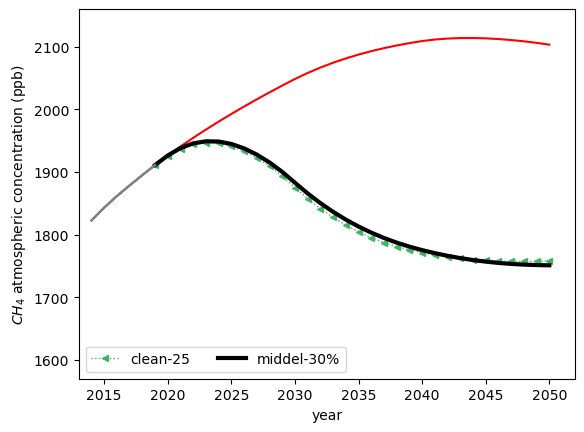

In [132]:
fig, ax = plt.subplots()

ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_real.isel(scen=0).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,#label='no-GMP',
         linestyle='-',color='r')

scen_1_list = ['p','m','c']
scen_2_list = [4,3,2,1,0]

linestyle_list = [':',':','-','--','--']
linewidth_list = [1,1,3,1,1]
color_list = ['#741A88','k','#41B365',]
marker_list = ['<','<','','x','x']

label_1_list = ['polluted','middel','clean']
label_2_list = ['20%','25','30%','35%','40%']

scen_list = ['m2','c3']

for y in scen_2_list:
    for x in scen_1_list:
        scen = x+str(y)
        
        if scen  not in scen_list:
            continue
        
        i = scen_1_list.index(x)
        j = scen_2_list.index(y)
        ax.plot(Out_scen_gmp.year.sel(year=slice(2019,2050)),Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0,
                label=label_1_list[i]+'-'+label_2_list[j],
                linestyle=linestyle_list[j],color=color_list[i],linewidth=linewidth_list[j],
               marker=marker_list[j],markersize=4
               )
        if y == 2:
            print(scen)
            print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0).max().values)
#             print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0).values)
#             print((Out_scen_gmp_change_polluted.sel(scen=scen).D_CH4.mean('config').sel(year=slice(2019,2050))+Par0.CH4_0)[-1].values)
ax.plot(Out_scen_real.year.sel(year=slice(2014,2019)),Out_scen_gmp.D_CH4.sel(year=slice(2014,2019)).mean('config')+Par0.CH4_0,color='grey')
ax.legend(ncol=3,loc='lower left')


ax.set_ylabel('$CH_4$ atmospheric concentration (ppb)')
ax.set_xlabel('year')

ax.set_ylim(1570,2160)
ax.set_xlim(2013,2052)

fig.savefig('GMP-extended.pdf',dpi=300)

分解到NOX、CO、VOC

In [133]:
For_scen_gmp_clean = For_scen_gmp.sel(scen=['middle','clean','middle','middle','middle']).copy(deep=True).assign_coords(scen=np.array(['middle','clean','clean-NOX','clean-CO','clean-VOC']))

In [134]:
For_scen_gmp_clean['E_NOX'][:,:,2] = For_scen_gmp_clean['E_NOX'][:,:,1] #NOX
For_scen_gmp_clean['E_CO'][:,:,3] = For_scen_gmp_clean['E_CO'][:,:,1] #CO
For_scen_gmp_clean['E_VOC'][:,:,4] = For_scen_gmp_clean['E_VOC'][:,:,1] #VOC

In [135]:
Out_scen_gmp_clean = OSCAR(Ini=Ini, Par=Par_tmp, For=For_scen_gmp_clean, var_keep=var_keep+['f_kOH','f_kOH_O3P']+['RF'], nt=4)

OSCAR_v3 running
year = 2050 (nt = 4)
total running time: 4.8 minutes


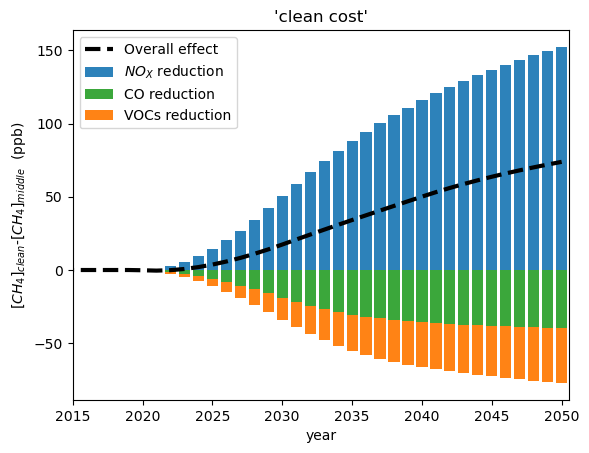

In [159]:
f, ax = plt.subplots()

temp = Out_scen_gmp_clean.D_CH4.mean('config')-Out_scen_gmp_clean.D_CH4.mean('config').isel(scen=0)

ax.plot(temp.year,temp.sel(scen='clean'),color='k',label='Overall effect',linestyle='--',linewidth=3)
# ax.plot(temp.year,temp.sel(scen=['clean-NOX','clean-CO','clean-VOC']).sum('scen'),color='grey',linestyle='--')

ax.bar(temp.year,temp.sel(scen='clean-NOX'),label='$NO_X$ reduction',linewidth=5,color='#2D82BA')

ax.bar(temp.year,temp.sel(scen='clean-VOC')+temp.sel(scen='clean-CO'),linewidth=5,color='#FF8315')
ax.bar(temp.year,temp.sel(scen='clean-CO'),label='CO reduction',linewidth=5,color='#3BA73B')
ax.bar(0,0,label='VOCs reduction',linewidth=5,color='#FF8315')

ax.legend()

ax.set_xlabel('year')
ax.set_ylabel('$[CH_4]_{clean}$-$[CH_4]_{middle}$  (ppb)')
ax.set_title("'clean cost'")
ax.set_xlim(2015,2050.5)
f.savefig('Fig4a.pdf',dpi=300)

In [165]:
temp.sel(scen='clean-VOC')

<xarray.DataArray 'D_CH4' (year: 37)>
array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,  -0.10072539,  -0.48375236,
        -1.16882361,  -2.13460777,  -3.35955614,  -4.82184708,
        -6.49959433,  -8.37113778, -10.41528319, -12.61152608,
       -14.94006151, -17.26014027, -19.37037947, -21.28773431,
       -23.02888019, -24.60962953, -26.0445439 , -27.34707803,
       -28.52949439, -29.6031294 , -30.57837163, -31.47266449,
       -32.30597144, -33.08425838, -33.81323682, -34.49820528,
       -35.14410514, -35.75532019, -36.33581655, -36.88897016,
       -37.41756774])
Coordinates:
    scen     <U9 'clean-VOC'
  * year     (year) int64 2014 2015 2016 2017 2018 ... 2046 2047 2048 2049 2050

In [137]:
For_scen_gmp_polluted = For_scen_gmp.sel(scen=['middle','polluted','middle','middle','middle']).copy(deep=True).assign_coords(scen=np.array(['middle','polluted','polluted-NOX','polluted-CO','polluted-VOC']))

In [138]:
For_scen_gmp_polluted['E_NOX'][:,:,2] = For_scen_gmp_polluted['E_NOX'][:,:,1] #NOX
For_scen_gmp_polluted['E_CO'][:,:,3] = For_scen_gmp_polluted['E_CO'][:,:,1] #CO
For_scen_gmp_polluted['E_VOC'][:,:,4] = For_scen_gmp_polluted['E_VOC'][:,:,1] #VOC

In [139]:
Out_scen_gmp_polluted = OSCAR(Ini=Ini, Par=Par_tmp, For=For_scen_gmp_polluted, var_keep=var_keep+['f_kOH','f_kOH_O3P']+['RF'], nt=4)

OSCAR_v3 running
year = 2050 (nt = 4)
total running time: 4.8 minutes


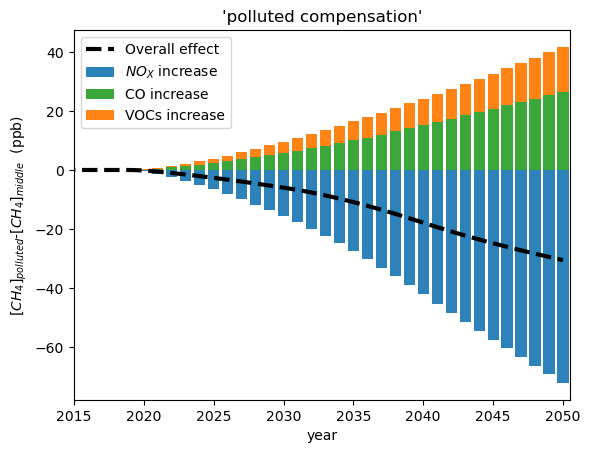

In [166]:
f, ax = plt.subplots()

temp = Out_scen_gmp_polluted.D_CH4.mean('config')-Out_scen_gmp_polluted.D_CH4.mean('config').isel(scen=0)

ax.plot(temp.year,temp.sel(scen='polluted'),color='k',label='Overall effect',linestyle='--',linewidth=3)
# ax.plot(temp.year,temp.sel(scen=['clean-NOX','clean-CO','clean-VOC']).sum('scen'),color='grey',linestyle='--')

ax.bar(temp.year,temp.sel(scen='polluted-NOX'),label='$NO_X$ increase',linewidth=5,color='#2D82BA')

ax.bar(temp.year,temp.sel(scen='polluted-VOC')+temp.sel(scen='polluted-CO'),linewidth=5,color='#FF8315')
ax.bar(temp.year,temp.sel(scen='polluted-CO'),label='CO increase',linewidth=5,color='#3BA73B')
ax.bar(0,0,label='VOCs increase',linewidth=5,color='#FF8315')

ax.legend()

ax.set_xlabel('year')
ax.set_ylabel('$[CH_4]_{polluted}$-$[CH_4]_{middle}$  (ppb)')
ax.set_title("'polluted compensation'")
ax.set_xlim(2015,2050.5)
f.savefig('Fig4b.pdf',dpi=300)

In [172]:
temp.sel(scen='polluted-VOC')

<xarray.DataArray 'D_CH4' (year: 37)>
array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.0646947 ,  0.25534763,  0.49807132,  0.78877978,
        1.12342389,  1.49793245,  1.90825786,  2.3504271 ,  2.82058314,
        3.31502367,  3.83019265,  4.35583876,  4.87887076,  5.39920396,
        5.91698391,  6.43246498,  6.94589362,  7.45753262,  7.96760889,
        8.4763826 ,  8.98411982,  9.5029386 , 10.05102254, 10.62616759,
       11.22645991, 11.8502021 , 12.49592346, 13.16223426, 13.84788453,
       14.55162341, 15.27215687])
Coordinates:
    scen     <U12 'polluted-VOC'
  * year     (year) int64 2014 2015 2016 2017 2018 ... 2046 2047 2048 2049 2050